# Chapter 14 | Worked solutions

*Selective State Spaces*

All ten exercises are solved here in chapter order. We follow the old state and
the new write separately, connect step size to a sigmoid gate, and compare
recurrent, dense, and chunked evaluations. The last exercises test causality,
an exact discrete reset, and what a memory experiment can actually establish.
The written PDF contains every explanation and figure. The notebook PDF also
contains the executed code and recorded results.

Open this notebook inside `transformers-book` and run the cells in order
with Python, NumPy, and Matplotlib installed. All calculations run on CPU
using float64. These are numerical teaching examples, not a trained Mamba model
or GPU speed measurements.

In [1]:
from pathlib import Path
import sys

import numpy as np

working_directory = Path.cwd()
for repo_root in (working_directory, *working_directory.parents):
    model_path = (
        repo_root / "examples" / "ch14_selective_ssm"
    )
    if model_path.is_dir():
        sys.path.insert(0, str(repo_root))
        break
else:
    raise FileNotFoundError(
        "Open this notebook inside transformers-book."
    )
import matplotlib.pyplot as plt
%matplotlib inline

BLUE, TEAL, ORANGE = "#3976af", "#46856e", "#bb783d"
plt.rcParams.update({"figure.figsize": (8.6, 3.4), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})


## 1. Trace a selective state

The update is $x_t=a_tx_{t-1}+(1-a_t)u_t$. First multiply the old
state by its retention, then add the new input multiplied by its write coefficient.
Use the updated state from one row as the old state in the next row.

| Position | Input | Old-state part | New-write part | Updated state |
| --: | --: | --: | --: | --: |
| 1 | 4 | $(1/2)0=0$ | $(1/2)4=2$ | $2$ |
| 2 | 10 | $(9/10)2=9/5$ | $(1/10)10=1$ | $14/5=2.8$ |
| 3 | 2 | $(1/4)(14/5)=7/10$ | $(3/4)2=3/2$ | $11/5=2.2$ |

At position 2, the state moves from 2 to 2.8 toward input 10. It covers
$(2.8-2)/(10-2)=0.1$ of the distance. This is the write fraction $1-a_2$.
The new-write term itself is 1, while the net change of state is 0.8:
the update also discarded 0.2 of the old state. At position 3 the state
moves downward because the new input is smaller than the old state.

In [2]:
inputs = np.array([4.0, 10.0, 2.0])
retentions = np.array([0.5, 0.9, 0.25])
state = 0.0
trace = []
print("Position  Retained old  New write  Updated state")
for t, (token, retain) in enumerate(zip(inputs, retentions), 1):
    old_part = retain * state
    write_part = (1 - retain) * token
    state = old_part + write_part
    trace.append(state)
    print(f"{t:>8}  {old_part:>12.3f}  {write_part:>9.3f}  {state:>13.3f}")
np.testing.assert_allclose(trace, [2, 2.8, 2.2], rtol=0, atol=1e-14)
fraction = (trace[1] - trace[0]) / (inputs[1] - trace[0])
np.testing.assert_allclose(fraction, 0.1, rtol=0, atol=1e-14)
print("Fraction of distance covered at position 2:", round(fraction, 3))

Position  Retained old  New write  Updated state
       1         0.000      2.000          2.000
       2         1.800      1.000          2.800
       3         0.700      1.500          2.200
Fraction of distance covered at position 2: 0.1


## 2. Connect the step to the write

Hold the input $u$ constant over the interval. The equation $\dot{x}=-x+u$
means that the difference $d=x-u$ satisfies $\dot{d}=-d$.
After an interval of length $\Delta$, the difference is multiplied by
$a=e^{-\Delta}$. Thus $x_{\rm end}=u+a(x_{\rm start}-u)$.

| Step $\Delta$ | Retention $a$ | Write $1-a$ | Control score $z$ |
| :-- | --: | --: | --: |
| $\ln 2$ | $1/2$ | $1/2$ | $0$ |
| $\ln 4$ | $1/4$ | $3/4$ | $\ln 3$ |

The step $\ln 4$ moves the state farther toward the input: three quarters
of the starting distance instead of one half. From state 2 toward input 10,
the new states are 6 and 8. This distance argument also works when the input
lies below the starting state.

To recover the score, solve $\Delta=\log(1+e^z)$ for
$z=\log(e^\Delta-1)$. The sigmoid writes are $\sigma(0)=1/2$ and
$\sigma(\ln 3)=3/4$. The continuous-time step and the sigmoid gate
describe the same restricted scalar update.

In [3]:
from examples.ch14_selective_ssm.model import zoh_coefficients

steps = np.log([2.0, 4.0])
retain, write = zoh_coefficients(steps)
scores = np.log(np.expm1(steps))
sigmoid_write = 1 / (1 + np.exp(-scores))
np.testing.assert_allclose(retain, [0.5, 0.25])
np.testing.assert_allclose(write, [0.5, 0.75])
np.testing.assert_allclose(sigmoid_write, write)
print("Control scores:", scores)
print("Retentions:", retain, "Writes:", write)
print("From state 2 toward input 10:", retain * 2 + write * 10)

Control scores: [0.         1.09861229]
Retentions: [0.5  0.25] Writes: [0.5  0.75]
From state 2 toward input 10: [6. 8.]


## 3. Respect time order

Write the first map as $f(x)=0.8x+2$ and the second as $g(x)=0.5x-1$.
Substituting the first result into the second gives

$$g(f(x))=0.5(0.8x+2)-1=0.4x.$$

At $x=3$, the intermediate value is 4.4 and the final value is 1.2.
Reversing the order gives

$$f(g(x))=0.8(0.5x-1)+2=0.4x+1.2.$$

At the same starting value, this result is 2.4. The scalar slopes have
the same product in either order, but the later map scales the earlier
map's write. That makes the offsets different.

Append $h(x)=0.25x+3$. Grouping $f$ and $g$ first gives
$h(g(f(x)))=0.25(0.4x)+3=0.1x+3$.
Grouping $g$ and $h$ first gives $h(g(x))=0.125x+2.75$;
then $(h\circ g)(f(x))=0.125(0.8x+2)+2.75=0.1x+3$.
Both groupings return 3.3 at $x=3$. We changed parentheses without
changing which update came first.

In [4]:
from examples.ch14_selective_ssm.model import compose_diagonal

first, second, third = (0.8, 2.0), (0.5, -1.0), (0.25, 3.0)
forward = compose_diagonal(first, second)
reverse = compose_diagonal(second, first)
left = compose_diagonal(compose_diagonal(first, second), third)
right = compose_diagonal(first, compose_diagonal(second, third))
np.testing.assert_allclose(forward, [0.4, 0.0], rtol=0, atol=1e-14)
np.testing.assert_allclose(reverse, [0.4, 1.2], rtol=0, atol=1e-14)
np.testing.assert_allclose(left, right, rtol=0, atol=1e-14)
np.testing.assert_allclose(left, [0.1, 3.0], rtol=0, atol=1e-14)
for name, pair in [("First then second", forward), ("Reverse", reverse),
                   ("Three, left grouping", left), ("Three, right grouping", right)]:
    slope, offset = pair
    print(name, "->", tuple(round(float(v), 4) for v in pair),
          "; at x=3:", round(float(slope * 3 + offset), 4))

First then second -> (0.4, 0.0) ; at x=3: 1.2
Reverse -> (0.4, 1.2) ; at x=3: 2.4
Three, left grouping -> (0.1, 3.0) ; at x=3: 3.3
Three, right grouping -> (0.1, 3.0) ; at x=3: 3.3


## 4. Follow one input to a read

The write at position $s$ is added after that position's retention has
acted on the old state. It crosses transitions $s+1$ through 3 before
the final read $\mathbf{c}_3=(2,-1)$.

| Source $s$ | Transitions crossed | Retention product | Read--write product | $M_{3,s}$ |
| --: | :-- | --: | --: | --: |
| 1 | At positions 2 and 3 | $0.5(0.8)=0.4$ | $2(1)-1(2)=0$ | $0$ |
| 2 | At position 3 | $0.8$ | $2(0)-1(1)=-1$ | $-0.8$ |
| 3 | None | $1$ | $2(1)-1(0)=2$ | $2$ |

Thus row 3 is $(0,-0.8,2)$ and $y_3=-0.8u_2+2u_3$ when the
initial state is zero. The factor $a_1=0.6$ acts on the initial state,
so it is absent from every input coefficient in this row. If the initial
state were nonzero, its separate contribution would be
$a_3a_2a_1\mathbf{c}_3\mathbf{x}_0$.

A zero output contribution does not imply a zero state contribution.
One unit of input 1 leaves the nonzero vector $(0.4,0.8)^\top$ at
position 3. This particular read takes twice the first coordinate and
subtracts the second, producing zero. A different read could expose it.
The negative and greater-than-one entries also show why these are not
softmax probabilities.

In [5]:
from examples.ch14_selective_ssm.model import causal_decay

row_a = np.array([0.6, 0.5, 0.8])
row_b = np.array([[1, 2], [0, 1], [1, 0]])
last_read = np.array([2, -1])
row = causal_decay(row_a)[2] * (row_b @ last_read)
carried_first = row_a[1] * row_a[2] * row_b[0]
np.testing.assert_allclose(row, [0, -0.8, 2], rtol=0, atol=1e-14)
np.testing.assert_allclose(carried_first, [0.4, 0.8])
print("Row 3:", row)
print("Input 1's carried vector per unit:", carried_first)
print("Its contribution to this read:", last_read @ carried_first)

Row 3: [ 0.  -0.8  2. ]
Input 1's carried vector per unit: [0.4 0.8]
Its contribution to this read: 0.0


## 5. Inspect a small step numerically

Hold the input fixed during a short interval of length `delta`.
In the chapter's scalar zero-order-hold example, the fraction of
the old state that survives the interval is $a=e^{-\Delta}$.
The coefficient multiplying the input is $b=1-e^{-\Delta}$.
If the interval is very short, the state barely moves and $b$
is small. Its size is about $\Delta$, since
$e^{-\Delta}=1-\Delta+\Delta^2/2-\cdots$ near zero.

Computing `1 - np.exp(-delta)` first rounds the exponential
to a floating-point value near one. The subtraction exposes
the small difference, so an error of order $10^{-16}$ in
that rounded value can be a large fraction of the write.
This loss of significant digits is called **cancellation**.
The helper instead uses `-np.expm1(-delta)`.
The `expm1` operation evaluates $e^z-1$ directly and is
designed to retain accuracy when $z$ is close to zero.

In [6]:
from decimal import Decimal, localcontext

from examples.ch14_selective_ssm.model import zoh_coefficients

delta = np.array([1e-4, 1e-9, 1e-16], dtype=np.float64)
retain, write = zoh_coefficients(delta)
subtract = 1.0 - np.exp(-delta)

# Compute the reference at 80 decimal digits, then round once.
with localcontext() as context:
    context.prec = 80
    reference = np.array([
        float(1 - (-Decimal.from_float(float(step))).exp())
        for step in delta
    ])

np.testing.assert_allclose(write, reference, rtol=2e-15, atol=0)
assert np.all(write > 0)
print(f"{'delta':>8}  {'stable write':>23}  {'subtraction':>23}")
for step, stable, direct in zip(delta, write, subtract):
    print(f"{step:8.1e}  {stable:23.16e}  {direct:23.16e}")

   delta             stable write              subtraction
 1.0e-04   9.9995000166662508e-05   9.9995000166663850e-05
 1.0e-09   9.9999999949999999e-10   9.9999997171806854e-10
 1.0e-16   9.9999999999999998e-17   1.1102230246251565e-16


The reference uses the same binary float64 input values as
NumPy. It performs the exponential and subtraction at much
higher precision before rounding the small result to float64.
The check allows a relative tolerance of $2\times10^{-15}$
and no absolute tolerance, so an erroneous zero would fail
even for the smallest positive write.

To measure the loss of precision, divide the absolute error
by the reference write for each step. Also try one extra,
smaller step to see when subtraction can return zero.

In [7]:
relative_stable = np.abs(write - reference) / reference
relative_subtract = np.abs(subtract - reference) / reference

print(f"{'delta':>8}  {'stable relative err':>19}  "
      f"{'subtract relative err':>21}")
for step, good, bad in zip(delta, relative_stable, relative_subtract):
    print(f"{step:8.1e}  {good:19.3e}  {bad:21.3e}")

tiny_delta = np.float64(1e-17)
tiny_retain, tiny_write = zoh_coefficients(tiny_delta)
print(f"Extra step: delta={tiny_delta:.1e}, retain={tiny_retain:.17g}")
print(f"1 - retain = {1.0 - tiny_retain:.17g}")
print(f"Stable write = {tiny_write:.17g}")

   delta  stable relative err  subtract relative err
 1.0e-04            0.000e+00              1.342e-14
 1.0e-09            0.000e+00              2.778e-08
 1.0e-16            0.000e+00              1.102e-01
Extra step: delta=1.0e-17, retain=1
1 - retain = 0
Stable write = 1.0000000000000001e-17


The saved float64 run gives the following write coefficients. The high-precision reference rounds to the stable values shown.

| Step | Stable write | Direct subtraction |
| :-- | :-- | :-- |
| $10^{-4}$ | $9.999500016666251\times10^{-5}$ | $9.999500016666385\times10^{-5}$ |
| $10^{-9}$ | $9.999999995\times10^{-10}$ | $9.999999717180685\times10^{-10}$ |
| $10^{-16}$ | $1.0\times10^{-16}$ | $1.110223024625157\times10^{-16}$ |

For the extra step $10^{-17}$, direct subtraction returns zero and the stable write is $10^{-17}$.

At $10^{-4}$, direct subtraction may lose only the last few digits.
At $10^{-9}$ and $10^{-16}$, rounding the exponential can cause a much
larger relative error in the small write. For example, returning the
float64 gap $1.11022\times10^{-16}$ instead of $10^{-16}$ is about
11 percent too large. The exact last digits depend on the exponential
implementation; the table records this run.

When the rounded exponential is exactly one, subtraction returns zero.
The extra step $10^{-17}$ illustrates that limit on this platform.
The stable helper keeps the small positive write even when the retention
rounds to one. In exact arithmetic, the two coefficients still sum to one.

## 6. Give the coordinates different retentions

Now let the state hold two numbers. A row of `a` supplies
the retention for each coordinate at that time step.
The rows of `b` are all $(1,1)$, so each new scalar input
is written to both coordinates without scaling. The rows
of `c` are also $(1,1)$, so the readout is the sum of
the two coordinates after the update.

With separate retentions, the update is

$$
x_{t,1}=\tfrac14 x_{t-1,1}+u_t,\qquad
x_{t,2}=\tfrac34 x_{t-1,2}+u_t,\qquad
y_t=x_{t,1}+x_{t,2}.
$$

These write coefficients are specified independently of the
retention. The rule $b=1-a$ in Exercise 5 came from one
particular scalar system.

| Time $t$ | Input $u_t$ | State $(x_{t,1},x_{t,2})$ | Readout |
| --: | --: | :-- | --: |
| 1 | 2 | $(0+2,\ 0+2)=(2,2)$ | $4$ |
| 2 | 0 | $(2/4,\ 3(2)/4)=(1/2,3/2)$ | $2$ |
| 3 | 1 | $(1/8+1,\ 9/8+1)=(9/8,17/8)$ | $13/4$ |

The second input is zero, which isolates the two retentions.
The coordinates enter that step with the same value, 2.
The first carries $1/2$ forward and the second carries $3/2$
forward because it retains a larger fraction.

In [8]:
from examples.ch14_selective_ssm.model import selective_scan

scan_u = np.array([2.0, 0.0, 1.0])
scan_a = np.tile([0.25, 0.75], (len(scan_u), 1))
scan_b = np.ones((len(scan_u), 2))
scan_c = np.ones_like(scan_b)
assert scan_a.shape == scan_b.shape == scan_c.shape == (3, 2)
separate_y, separate_states = selective_scan(
    scan_u, scan_a, scan_b, scan_c,
)

expected_separate = np.array([[2, 2], [1/2, 3/2], [9/8, 17/8]])
np.testing.assert_allclose(
    separate_states, expected_separate, rtol=0, atol=1e-12,
)
np.testing.assert_allclose(separate_y, [4, 2, 13/4], rtol=0,
                           atol=1e-12)
print("Separate retention shape", scan_a.shape)
print("States (one row per input)")
print(separate_states)
print("Outputs", separate_y)

Separate retention shape (3, 2)
States (one row per input)
[[2.    2.   ]
 [0.5   1.5  ]
 [1.125 2.125]]
Outputs [4.   2.   3.25]


Give `a` shape $[3,1]$ to store one retention per time step.
The scan multiplies a length-one row by the two-coordinate
state. NumPy **broadcasts** the length-one row, meaning its
single value is used for both multiplications. The state,
write, and read widths remain two.

Starting from equal states, the coordinates now receive the
same retention and the same write, so they stay equal.
After reading 2, each coordinate is 2. After reading 0, each
is $2/4=1/2$. The final input of 1 gives
$(1/4)(1/2)+1=9/8$ per coordinate. The outputs are therefore
$(4,1,9/4)$. Use absolute tolerance $10^{-12}$ and zero
relative tolerance for these float64 state and output checks.

In [9]:
shared_a = np.full((len(scan_u), 1), 0.25)
shared_y, shared_states = selective_scan(
    scan_u, shared_a, scan_b, scan_c,
)
expected_shared = np.array([[2, 2], [1/2, 1/2], [9/8, 9/8]])
np.testing.assert_allclose(
    shared_states, expected_shared, rtol=0, atol=1e-12,
)
np.testing.assert_allclose(
    shared_y, [4, 1, 9/4], rtol=0, atol=1e-12,
)
np.testing.assert_allclose(
    separate_y - shared_y, [0, 1, 1], rtol=0, atol=1e-12,
)

print("Shared retention shape", shared_a.shape)
print("States (one row per input)")
print(shared_states)
print("Outputs", shared_y)
print("Separate minus shared", separate_y - shared_y)

Shared retention shape (3, 1)
States (one row per input)
[[2.    2.   ]
 [0.5   0.5  ]
 [1.125 1.125]]
Outputs [4.   1.   2.25]
Separate minus shared [0. 1. 1.]


The first outputs agree because the initial state is zero
and both runs apply the same write. The last two outputs
in the separate-retention run are each one larger.
The first coordinate uses $1/4$ in both runs and contributes
no difference. At time 2 the second coordinate differs by
$3/2-1/2=1$. At time 3 its retained contributions differ
by $(3/4)(3/2)-(1/4)(1/2)=1$ before the same new input
is added to both. This is a difference in the stored state
that the readout exposes.

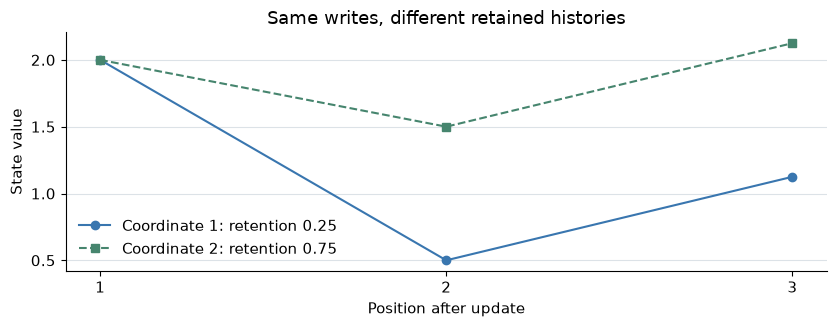

In [10]:
positions = np.arange(1, 4)
fig, ax = plt.subplots()
ax.plot(positions, separate_states[:, 0], "-o", color=BLUE,
        label="Coordinate 1: retention 0.25")
ax.plot(positions, separate_states[:, 1], "--s", color=TEAL,
        label="Coordinate 2: retention 0.75")
ax.set(xlabel="Position after update", ylabel="State value", xticks=positions,
       title="Same writes, different retained histories")
ax.grid(axis="y", color="#dce2e7")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

The zero input at position 2 makes the retention difference visible.
Both coordinates started that update at 2, but one falls to 0.5 and
the other to 1.5. The final input adds one to both retained values;
it does not erase their different histories.

## 7. Move the chunk boundary

A chunk is a group of consecutive positions processed together.
Changing its size moves the boundary where the algorithm must
pass its state forward. The sequence and the recurrence are
the same for every boundary choice.

Here each state has one coordinate, and each write and read
coefficient is one. Starting from $x_0=0$, the recurrence is
$x_t=a_tx_{t-1}+u_t$ and the output is $y_t=x_t$. The manuscript
numbers positions from one. NumPy row 0 therefore refers to
position 1 in the calculations below.

| Position $t$ | Retention $a_t$ | Input $u_t$ | Retained state | State and output $x_t=y_t$ |
| --: | --: | --: | --: | --: |
| 1 | $1/2$ | 1 | 0 | 1 |
| 2 | $1/4$ | 2 | $1/4$ | $9/4$ |
| 3 | $3/4$ | 0 | $27/16$ | $27/16$ |
| 4 | $1/2$ | 3 | $27/32$ | $123/32$ |
| 5 | $1/4$ | 1 | $123/128$ | $251/128$ |

In the dense calculation, row $t$ of $M$ tells us how each
input contributes to $y_t$. An input written at $s$ enters
with coefficient one. It passes through the retentions at
positions $s+1$ through $t$ before it is read. Thus
$M_{t,s}=\prod_{i=s+1}^t a_i$ for $s\le t$.
The empty product on the diagonal equals one. For $s>t$ the
input is still in the future and its coefficient is zero.

$$
M=
\begin{bmatrix}
1 & 0 & 0 & 0 & 0\\
1/4 & 1 & 0 & 0 & 0\\
3/16 & 3/4 & 1 & 0 & 0\\
3/32 & 3/8 & 1/2 & 1 & 0\\
3/128 & 3/32 & 1/8 & 1/4 & 1
\end{bmatrix}.
$$

For instance, the input at position 2 passes through
$a_3=3/4$ and $a_4=1/2$ to reach output 4. Its coefficient
is $3/8$, which multiplies $u_2=2$. Multiplying the whole
fourth row by $u$ gives $3/32+(3/8)2+(1/2)0+3=123/32$,
exactly the fourth output of the recurrence.

In [11]:
from examples.ch14_selective_ssm.model import (
    ssd_chunked,
    ssd_dense,
    ssd_recurrent,
)

chunk_u = np.array([1.0, 2.0, 0.0, 3.0, 1.0])
chunk_a = np.array([0.5, 0.25, 0.75, 0.5, 0.25])
chunk_b = np.ones((5, 1))
chunk_c = np.ones((5, 1))
chunk_atol = 1e-12

chunk_dense, chunk_matrix = ssd_dense(
    chunk_u, chunk_a, chunk_b, chunk_c
)
chunk_recurrent, chunk_states = ssd_recurrent(
    chunk_u, chunk_a, chunk_b, chunk_c
)

Check the matrix and both output vectors against the hand calculations.

In [12]:
expected_matrix = np.array([
    [1, 0, 0, 0, 0],
    [1/4, 1, 0, 0, 0],
    [3/16, 3/4, 1, 0, 0],
    [3/32, 3/8, 1/2, 1, 0],
    [3/128, 3/32, 1/8, 1/4, 1],
])
expected_output = np.array([1, 9/4, 27/16, 123/32, 251/128])
np.testing.assert_allclose(
    chunk_matrix, expected_matrix, rtol=0, atol=chunk_atol
)
np.testing.assert_allclose(
    chunk_dense, expected_output, rtol=0, atol=chunk_atol
)
np.testing.assert_allclose(
    chunk_recurrent, expected_output, rtol=0, atol=chunk_atol
)
np.testing.assert_allclose(
    chunk_states[:, 0], expected_output, rtol=0, atol=chunk_atol
)

print("Dense sequence matrix")
print(chunk_matrix)
print("Dense outputs    ", chunk_dense)
print("Recurrent outputs", chunk_recurrent)
print("State trace      ", chunk_states[:, 0])

Dense sequence matrix
[[1.        0.        0.        0.        0.       ]
 [0.25      1.        0.        0.        0.       ]
 [0.1875    0.75      1.        0.        0.       ]
 [0.09375   0.375     0.5       1.        0.       ]
 [0.0234375 0.09375   0.125     0.25      1.       ]]
Dense outputs     [1.        2.25      1.6875    3.84375   1.9609375]
Recurrent outputs [1.        2.25      1.6875    3.84375   1.9609375]
State trace       [1.        2.25      1.6875    3.84375   1.9609375]


A chunk first computes what its own inputs would produce
with a zero incoming state. Then it adds the contribution
of the actual incoming state, which is multiplied by every
retention from the start of the chunk through the position
being read. Those are two different products. A local write
skips its own position's retention, while the incoming state
has to pass through that retention.

With chunk size 3, the first group covers positions 1–3 and
leaves state $x_3=27/16$. The group at positions 4–5 is shorter.
Its inputs $(3,1)$ would give $(3,7/4)$ if this group started
from zero. The state from position 3 adds $(27/32,27/128)$,
because it is first multiplied by $1/2$ and then by $1/4$.
The sum is $(123/32,251/128)$. The final state is $251/128$.

Chunk size 1 passes a state after every position. Size 5
contains the whole sequence in one block. Sizes 2 and 3
both need a shorter last block. The assertions below use
float64, with an absolute tolerance of $10^{-12}$ and zero
relative tolerance. Compare each output array to both
references and the returned state to the final recurrent
row of shape `[1]`.

In [13]:
print("Size  Block lengths     Max |error|   Final state")
for size in (1, 2, 3, 5):
    output, final = ssd_chunked(
        chunk_u, chunk_a, chunk_b, chunk_c, chunk_size=size
    )
    for reference in (chunk_dense, chunk_recurrent):
        np.testing.assert_allclose(
            output, reference, rtol=0, atol=chunk_atol
        )
    np.testing.assert_allclose(
        final, chunk_states[-1], rtol=0, atol=chunk_atol
    )
    lengths = [
        min(size, len(chunk_u) - start)
        for start in range(0, len(chunk_u), size)
    ]
    error = np.max(np.abs(output - chunk_recurrent))
    print(f"{size:>4}  {str(lengths):<17} {error:.2e}     {final[0]}")

Size  Block lengths     Max |error|   Final state
   1  [1, 1, 1, 1, 1]   0.00e+00     1.9609375
   2  [2, 2, 1]         0.00e+00     1.9609375
   3  [3, 2]            0.00e+00     1.9609375
   5  [5]               0.00e+00     1.9609375


All four chunk sizes agree with the hand calculation.
The full sequence matrix displays every possible input–output
path in one array. The chunked method evaluates only local
blocks directly. It carries the effect of previous blocks in
the state at each boundary, which is sufficient for this
recurrence.

In [14]:
local_last, _ = ssd_dense(
    chunk_u[3:], chunk_a[3:], chunk_b[3:], chunk_c[3:]
)
incoming_last = np.cumprod(chunk_a[3:]) * (chunk_c[3:] @ chunk_states[2])
np.testing.assert_allclose(local_last, [3, 7/4], rtol=0, atol=chunk_atol)
np.testing.assert_allclose(incoming_last, [27/32, 27/128], rtol=0,
                           atol=chunk_atol)
np.testing.assert_allclose(local_last + incoming_last, expected_output[3:],
                           rtol=0, atol=chunk_atol)
print("Local from zero:", local_last)
print("From incoming state:", incoming_last)
print("Sum:", local_last + incoming_last)

Local from zero: [3.   1.75]
From incoming state: [0.84375   0.2109375]
Sum: [3.84375   1.9609375]


## 8. Check causality within a chunk (optional)

Keep the five-position example from Exercise 7 and use chunks
of sizes 3 and 2. Change only the third input, from 0 to 4.
The first two inputs now share a chunk with an edited future
input. We want their outputs to remain unchanged even though
the code computes the chunk together.

The local matrix of the first chunk is the upper-left
$3\times3$ block of $M$.

$$
M_{\mathrm{local}}=
\begin{bmatrix}
1 & 0 & 0\\
1/4 & 1 & 0\\
3/16 & 3/4 & 1
\end{bmatrix}.
$$

The first two rows have zeros in column 3. The third row
has a one there because the current input is written before
its state is read. The change of 4 therefore adds $(0,0,4)$
to the first chunk's outputs. The change to its outgoing
state is also 4. It passes through retentions $1/2$ and $1/4$
in the next chunk, adding 2 at position 4 and $1/2$ at
position 5. The output difference across the full sequence
should be $(0,0,4,2,1/2)$.

In [15]:
future_u = chunk_u.copy()
future_u[2] = 4.0
before_edit, _ = ssd_chunked(
    chunk_u, chunk_a, chunk_b, chunk_c, chunk_size=3
)
after_edit, _ = ssd_chunked(
    future_u, chunk_a, chunk_b, chunk_c, chunk_size=3
)
edit_difference = after_edit - before_edit

np.testing.assert_array_equal(before_edit[:2], after_edit[:2])
np.testing.assert_allclose(
    edit_difference, [0, 0, 4, 2, 0.5], rtol=0, atol=chunk_atol
)
np.testing.assert_allclose(
    edit_difference, 4 * chunk_matrix[:, 2], rtol=0, atol=chunk_atol
)

print("First chunk's local matrix")
print(chunk_matrix[:3, :3])
print("Before", before_edit)
print("After ", after_edit)
print("Change", edit_difference)

First chunk's local matrix
[[1.     0.     0.    ]
 [0.25   1.     0.    ]
 [0.1875 0.75   1.    ]]
Before [1.        2.25      1.6875    3.84375   1.9609375]
After  [1.        2.25      5.6875    5.84375   2.4609375]
Change [0.  0.  4.  2.  0.5]


The first two outputs remain $(1,2.25)$. Output 3
increases by 4 and output 4 increases by 2. The triangular
local matrix prevents the edit from moving backward within
its own chunk, while the state at the boundary carries the
edit forward to the next one.

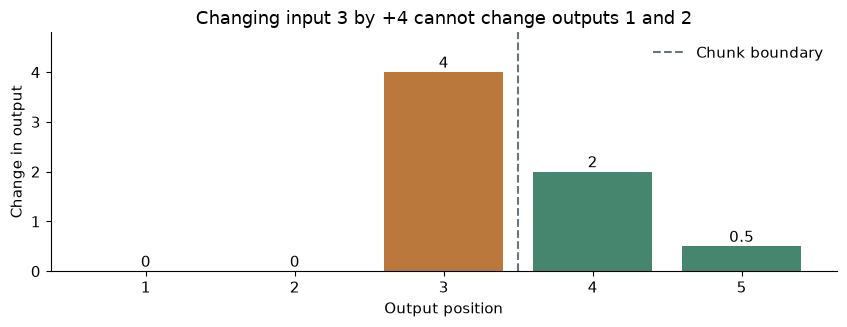

In [16]:
positions = np.arange(1, 6)
fig, ax = plt.subplots()
ax.bar(positions, edit_difference, color=[BLUE, BLUE, ORANGE, TEAL, TEAL])
ax.axvline(3.5, color="#687580", linestyle="--", label="Chunk boundary")
ax.set(xlabel="Output position", ylabel="Change in output", xticks=positions,
       ylim=(0, 4.8), title="Changing input 3 by +4 cannot change outputs 1 and 2")
for t, value in zip(positions, edit_difference):
    ax.text(t, value + 0.09, f"{value:g}", ha="center")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
plt.show()

The influence travels only forward. It changes the current output by 4,
then crosses the chunk boundary and is reduced by retentions 0.5 and 0.25.
The triangle within the first chunk and the state passed to the second
chunk enforce the same causal rule.

## 9. Reset a state inside a chunk (optional)

Use chunk size 3 again. Set $u_3=4$ and this time also set
$a_3=0$. Compare a warm start with $x_0=2$ to a cold start
with $x_0=0$. Since $b_t=c_t=1$ for every position, the state
is again the output. The first two transitions still let the
initial state contribute. At position 3, the update is
$x_3=0\cdot x_2+1\cdot4=4$ in both runs.

| Position $t$ | Warm output | Cold output | Warm minus cold |
| --: | --: | --: | --: |
| 1 | $(1/2)2+1=2$ | 1 | 1 |
| 2 | $(1/4)2+2=5/2$ | $9/4$ | $1/4$ |
| 3 | 4 | 4 | 0 |
| 4 | $(1/2)4+3=5$ | 5 | 0 |
| 5 | $(1/4)5+1=9/4$ | $9/4$ | 0 |

The two runs have the same inputs and coefficients. Their
state difference starts at 2 and evolves by
$\delta_t=a_t\delta_{t-1}$. Thus the contribution of the
initial state to output $t$ is $2\prod_{i=1}^t a_i$.
The product contains a zero starting at position 3.
This predicts that only outputs 1 and 2 depend on which
initial state we choose.

In [17]:
reset_u = chunk_u.copy()
reset_a = chunk_a.copy()
reset_u[2] = 4.0
reset_a[2] = 0.0

warm, warm_final = ssd_chunked(
    reset_u, reset_a, chunk_b, chunk_c, chunk_size=3, x0=[2.0]
)
cold, cold_final = ssd_chunked(
    reset_u, reset_a, chunk_b, chunk_c, chunk_size=3, x0=[0.0]
)

Check the warm and cold runs against the references separately.

In [18]:
for x0, output, final, expected in (
    ([2.0], warm, warm_final, [2, 2.5, 4, 5, 2.25]),
    ([0.0], cold, cold_final, [1, 2.25, 4, 5, 2.25]),
):
    dense, reset_matrix = ssd_dense(
        reset_u, reset_a, chunk_b, chunk_c, x0=x0
    )
    recurrent, states = ssd_recurrent(
        reset_u, reset_a, chunk_b, chunk_c, x0=x0
    )
    for reference in (dense, recurrent, expected):
        np.testing.assert_allclose(
            output, reference, rtol=0, atol=chunk_atol
        )
    np.testing.assert_allclose(
        final, states[-1], rtol=0, atol=chunk_atol
    )

print("Warm start", warm)
print("Cold start", cold)
print("Difference", warm - cold)
print("Final state, warm and cold", warm_final, cold_final)

Warm start [2.   2.5  4.   5.   2.25]
Cold start [1.   2.25 4.   5.   2.25]
Difference [1.   0.25 0.   0.   0.  ]
Final state, warm and cold [2.25] [2.25]


The reset acts on the old state. The new write
$b_3u_3$ is added after that multiplication, so it can
still affect position 3 and later outputs. In the matrix,
an earlier write must cross $a_3$ to reach position 3 or
beyond, so those coefficients become zero. The coefficient
for the current input is $M_{3,3}=1$. The row of the
sequence matrix at position 3 is consequently
$(0,0,1,0,0)$. The first chunk now passes state 4 onward,
regardless of which initial state entered it.

In [19]:
initial_response = 2 * np.cumprod(reset_a)
np.testing.assert_allclose(
    warm - cold, initial_response, rtol=0, atol=chunk_atol
)
np.testing.assert_array_equal(reset_matrix[2], [0, 0, 1, 0, 0])
np.testing.assert_array_equal(reset_matrix[2:, :2], np.zeros((3, 2)))
print("Initial-state response", initial_response)
print("Matrix row at position 3", reset_matrix[2])

Initial-state response [1.   0.25 0.   0.   0.  ]
Matrix row at position 3 [0. 0. 1. 0. 0.]


The exact reset uses a coefficient supplied directly to the discrete update.
For a finite positive $\Delta$ in the scalar model, $e^{-\Delta}$ is strictly
positive in exact arithmetic. An exact zero is a limiting case, an explicit
reset, or a possible floating-point underflow. A merely small retention
leaves a merely small dependence on the earlier state.

## 10. Design two memory tests (optional)

Use the same history with two question variants: the first location and
the latest location of a named delivery. For example, let D17 visit
North, East, and South, with unrelated D42 reports inserted between them.
The correct answers for D17 are North and South. Include different first
and last locations so that always returning the latest cannot pass both tasks.

Choose eight location labels with equal tokenized lengths. Randomize IDs and
intermediate locations. Sample first and latest labels uniformly as an ordered
pair of distinct labels. Keep unrelated labels independent of the target answer.
Use a fixed question format and a deterministic answer rule, such as exactly one
location label. Reserve whole histories for evaluation; keep both queries and
all variants of one history in the same data split.

For a delay comparison, use 8, 32, 128, or 512 reports. Put the first target
assignment at report 2, an intermediate update near the middle, and the final
target update at report $R-2$. Fill other positions with neutral reports. Keep
the number of target updates and the final-update-to-question distance fixed.
Then replace neutral reports with unrelated deliveries or extra target updates
in separate comparisons. Match actual token counts and evidence positions after
tokenization, since equal report counts need not imply equal sequence lengths.

Report exact-match accuracy for each question, joint accuracy requiring both
answers to be correct, and the frequency with which the first-location answer
is incorrectly replaced by the latest location. Report these by length and
interference level. Uniform guessing among eight labels gives expected
accuracy $1/8$ for either individual question.

There is a crucial control: a fixed state can solve both tasks. For one named
delivery, store its first location once and overwrite a separate latest-location
slot at each target update. Other deliveries leave these slots unchanged.
A small oracle demonstrates the algorithm on two histories. The histories share the first location North and latest location South, but their second target locations are East and West, respectively.
It tests the task specification, not the performance of a learned SSM.

In [20]:
def first_and_latest(reports, target):
    first = latest = None
    for delivery, location in reports:
        if delivery == target:
            if first is None:
                first = location
            latest = location
    return first, latest

history_a = [("D17", "North"), ("D42", "West"),
             ("D17", "East"), ("D17", "South"), ("D42", "East")]
history_b = [("D17", "North"), ("D42", "West"),
             ("D17", "West"), ("D17", "South"), ("D42", "East")]
for history in (history_a, history_b):
    assert first_and_latest(history, "D17") == ("North", "South")
    print("Stored first and latest:", first_and_latest(history, "D17"))
print("Second D17 update:", history_a[2][1], "versus", history_b[2][1])

Stored first and latest: ('North', 'South')
Stored first and latest: ('North', 'South')
Second D17 update: East versus West


Both histories leave the oracle's two slots identical, yet their second target
locations differ: East versus West. If the query chooses an intermediate update
only after the history is processed, these two slots cannot always answer it.
For a broader probe, vary the number of target updates and choose a requested
update index after the history, with balanced answer labels. Include interior
indices and randomized locations. This makes first-and-latest storage insufficient.
The example demonstrates a limitation of that particular summary, not a theorem
that every finite state fails on every bounded task. If the target ID is also
revealed only after the history, the model must retain facts for multiple IDs;
report that additional task requirement separately.

Measure persistent inference memory just after the history and before the
question. Hold batch size and actual state/cache dtypes fixed. Sum live array
elements times their bytes per element across layers. For batch size one and
float32, an SSM state of shape $[1,d,N]$ occupies $4dN$ bytes. Add the short
convolution buffer and any other persistent history. An attention layer with
$T$ cached positions, $H_{\rm KV}$ heads, and key/value widths $d_k,d_v$ stores
$4T H_{\rm KV}(d_k+d_v)$ bytes of key/value payload. Count allocated capacity
separately when buffers reserve unused slots. Exclude weights and temporary
workspace from this particular persistent-history measurement.

For an illustrative one-layer count, choose $d=8$, $N=4$ and a convolution
buffer of shape $[1,8,3]$. Their float32 payloads total $128+96=224$ bytes.
With two KV heads and key/value widths 4, the attention payload is $64T$ bytes.
At $T=8,32,128,512$, that is $512,2048,8192,32768$ bytes. These are array-size
calculations, not measurements of a complete model or evidence about its accuracy.

In [21]:
element_bytes = np.dtype(np.float32).itemsize
state_values = 8 * 4
conv_values = 8 * 3
ssm_payload = element_bytes * (state_values + conv_values)
assert ssm_payload == 224
print("Illustrative persistent array payloads, one layer, float32")
print("Positions  SSM + convolution bytes  KV bytes")
for length in (8, 32, 128, 512):
    kv_payload = element_bytes * length * 2 * (4 + 4)
    print(f"{length:>9}  {ssm_payload:>23}  {kv_payload:>8}")
print("No learned-model accuracy or runtime has been measured here.")

Illustrative persistent array payloads, one layer, float32
Positions  SSM + convolution bytes  KV bytes
        8                      224       512
       32                      224      2048
      128                      224      8192
      512                      224     32768
No learned-model accuracy or runtime has been measured here.


Keep accuracy and memory results side by side. A fixed-size state can
retain the facts demanded by a particular task, while an inadequate learned
update may lose them. The extra historical-query probe helps distinguish
those possibilities from simply tracking the most recent value.